# GMM Assignment – Mixed Covariance Matrices

- Component 1: identity covariance matrix
- Component 2: diagonal covariance matrix
- Component 3: full covariance matrix


In [25]:
# --------------------------------------------------
# 1. Imports and experiment settings
# --------------------------------------------------
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA

N = 5000
K = 3

weights_1 = [0.2, 0.5, 0.3]
weights_2 = [0.4, 0.3, 0.3]

assert len(weights_1) == K and len(weights_2) == K
assert np.isclose(sum(weights_1), 1.0)
assert np.isclose(sum(weights_2), 1.0)

# Each class uses the same covariance pattern across its three components.
COVARIANCE_TYPE = "mixed"

print("Samples per class:", N)
print("Components per class:", K)
print("Class 1 weights:", weights_1)
print("Class 2 weights:", weights_2)
print("Covariance assignment:", COVARIANCE_TYPE)

Samples per class: 5000
Components per class: 3
Class 1 weights: [0.2, 0.5, 0.3]
Class 2 weights: [0.4, 0.3, 0.3]
Covariance assignment: mixed


In [26]:
# --------------------------------------------------
# 2. Custom Uniform Random Number Generator (LCG)
# --------------------------------------------------
seed_state = 12345

def simple_uniform():
    global seed_state
    m = 2**32
    a = 1664525
    c = 1013904223
    seed_state = (a * seed_state + c) % m
    return seed_state / m

In [27]:
# --------------------------------------------------
# 3. Box-Muller transformation
# --------------------------------------------------
def box_muller():
    u1 = simple_uniform()
    u2 = simple_uniform()

    while u1 <= 0:
        u1 = simple_uniform()

    z1 = np.sqrt(-2 * np.log(u1)) * np.cos(2 * np.pi * u2)
    z2 = np.sqrt(-2 * np.log(u1)) * np.sin(2 * np.pi * u2)
    return z1, z2

In [28]:
# --------------------------------------------------
# 4. Generate random mean vectors
# --------------------------------------------------
def generate_means(K, scale=5.5):
    means = []
    for _ in range(K):
        mean_x, mean_y = box_muller()
        means.append([scale * mean_x, scale * mean_y])
    return np.array(means, dtype=float)

means_1 = generate_means(K)
means_2 = generate_means(K)

print("Class 1 means:\n", np.round(means_1, 3))
print("Class 2 means:\n", np.round(means_2, 3))

Class 1 means:
 [[15.262  1.593]
 [-4.021 -4.556]
 [ 1.816  1.551]]
Class 2 means:
 [[ -6.216  -1.949]
 [  1.167  -5.471]
 [ -0.544 -13.952]]


In [29]:
# --------------------------------------------------
# 5. Define covariance matrices
# --------------------------------------------------
def make_covariances(kind, K):
    """
    Return one covariance matrix for each Gaussian component.

    Component 1: Identity covariance
    Component 2: Diagonal covariance
    Component 3: Full covariance

    The same pattern is used for Class 1 and Class 2.
    """
    if K != 3:
        raise ValueError("This mixed-covariance setup requires K = 3.")

    if kind != "mixed":
        raise ValueError("Covariance assignment must be 'mixed'.")

    matrices = [
        # Component 1: Identity covariance matrix
        [[1.0, 0.0],
         [0.0, 1.0]],

        # Component 2: Diagonal covariance matrix
        [[2.0, 0.0],
         [0.0, 0.5]],

        # Component 3: Full covariance matrix (non-zero off-diagonal terms)
        [[2.0, 0.8],
         [0.8, 1.0]]
    ]

    result = [np.asarray(m, dtype=float) for m in matrices]

    # Check that every covariance matrix is symmetric and positive definite.
    for cov in result:
        if not np.allclose(cov, cov.T):
            raise ValueError("Covariance matrix must be symmetric.")
        if np.min(np.linalg.eigvalsh(cov)) <= 0:
            raise ValueError("Covariance matrix must be positive definite.")

    return result


# Apply the same component-wise covariance pattern to both classes.
covariances_1 = make_covariances(COVARIANCE_TYPE, K)
covariances_2 = make_covariances(COVARIANCE_TYPE, K)

print("Class 1 covariance matrices:")
for component_number, cov in enumerate(covariances_1, start=1):
    print(f"Component {component_number}:")
    print(cov)

print("\\nClass 2 covariance matrices:")
for component_number, cov in enumerate(covariances_2, start=1):
    print(f"Component {component_number}:")
    print(cov)

Class 1 covariance matrices:
Component 1:
[[1. 0.]
 [0. 1.]]
Component 2:
[[2.  0. ]
 [0.  0.5]]
Component 3:
[[2.  0.8]
 [0.8 1. ]]
\nClass 2 covariance matrices:
Component 1:
[[1. 0.]
 [0. 1.]]
Component 2:
[[2.  0. ]
 [0.  0.5]]
Component 3:
[[2.  0.8]
 [0.8 1. ]]


In [30]:
# --------------------------------------------------
# 6. Generate Gaussian mixture data
# --------------------------------------------------
def generate_data(N, means, weights, covariances):
    data = np.zeros((N, 2))
    component_labels = np.zeros(N, dtype=int)

    cumulative_weights = np.cumsum(weights)

    for i in range(N):
        # Select component using the custom uniform generator
        u = simple_uniform()
        component = np.searchsorted(cumulative_weights, u, side="right")
        component = min(component, len(weights) - 1)

        # Generate a standard 2D normal vector using Box-Muller
        z = np.array(box_muller())

        # Transform standard normal into the selected covariance
        eigenvalues, eigenvectors = np.linalg.eigh(covariances[component])
        covariance_sqrt = (
            eigenvectors @ np.diag(np.sqrt(eigenvalues)) @ eigenvectors.T
        )

        point = means[component] + covariance_sqrt @ z
        data[i] = point
        component_labels[i] = component

    return data, component_labels

# Generate class samples in a fixed sequence
X1, components1 = generate_data(N, means_1, weights_1, covariances_1)
X2, components2 = generate_data(N, means_2, weights_2, covariances_2)

print("Class 1 shape:", X1.shape)
print("Class 2 shape:", X2.shape)
print("Total samples:", len(X1) + len(X2))
print("Class 1 component counts:", np.bincount(components1, minlength=K))
print("Class 2 component counts:", np.bincount(components2, minlength=K))

Class 1 shape: (5000, 2)
Class 2 shape: (5000, 2)
Total samples: 10000
Class 1 component counts: [ 970 2524 1506]
Class 2 component counts: [1991 1517 1492]


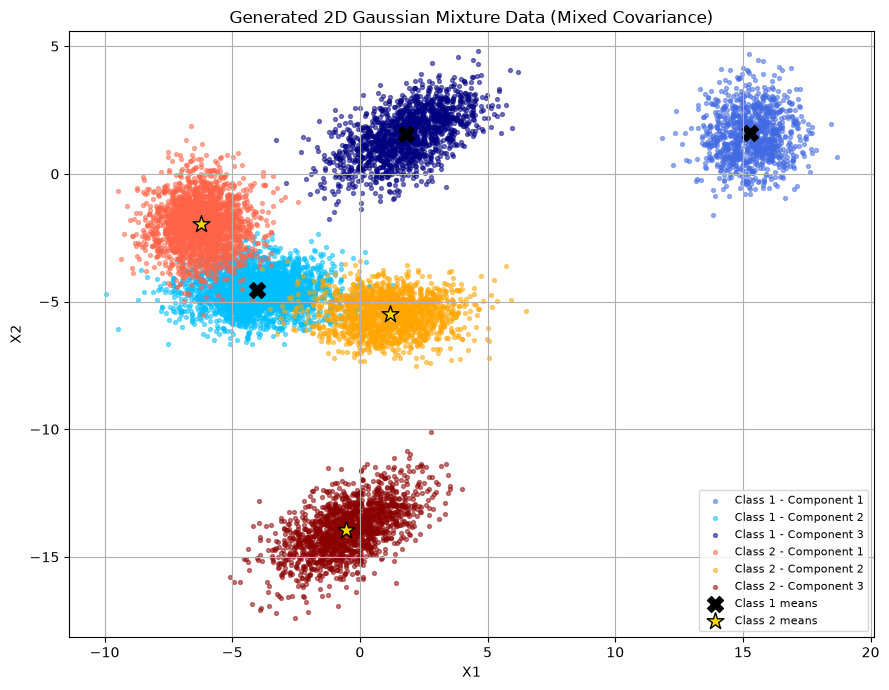

In [31]:
# --------------------------------------------------
# 7. Plot generated data
# --------------------------------------------------
colors_1 = ["royalblue", "deepskyblue", "navy"]
colors_2 = ["tomato", "orange", "darkred"]

plt.figure(figsize=(9, 7))

for k in range(K):
    mask = components1 == k
    plt.scatter(X1[mask, 0], X1[mask, 1], s=8, alpha=0.5,
                color=colors_1[k], label=f"Class 1 - Component {k+1}")

for k in range(K):
    mask = components2 == k
    plt.scatter(X2[mask, 0], X2[mask, 1], s=8, alpha=0.5,
                color=colors_2[k], label=f"Class 2 - Component {k+1}")

plt.scatter(means_1[:, 0], means_1[:, 1], marker="X", s=130,
            color="black", label="Class 1 means")
plt.scatter(means_2[:, 0], means_2[:, 1], marker="*", s=160,
            color="gold", edgecolor="black", label="Class 2 means")

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Generated 2D Gaussian Mixture Data (Mixed Covariance)")
plt.legend(fontsize=8)
plt.grid(True)
plt.axis("equal")
plt.tight_layout()
plt.show()

In [32]:
# --------------------------------------------------
# 8. 80:20 train-test split
# --------------------------------------------------
X1_train, X1_test = train_test_split(
    X1, test_size=0.2, random_state=42
)
X2_train, X2_test = train_test_split(
    X2, test_size=0.2, random_state=42
)

train_class_samples = [X1_train, X2_train]

print("Class 1 training:", X1_train.shape, " testing:", X1_test.shape)
print("Class 2 training:", X2_train.shape, " testing:", X2_test.shape)

Class 1 training: (4000, 2)  testing: (1000, 2)
Class 2 training: (4000, 2)  testing: (1000, 2)


In [33]:
# --------------------------------------------------
# 9. Custom K-Means
# --------------------------------------------------
class KMeans:
    def __init__(self, K=3, max_iter=100, tol=1e-6, random_state=42):
        self.K = K
        self.max_iter = max_iter
        self.tol = tol
        self.random_state = random_state
        self.centers = None

    def fit(self, X):
        rng = np.random.default_rng(self.random_state)
        indices = rng.choice(len(X), size=self.K, replace=False)
        self.centers = X[indices].astype(float)

        for _ in range(self.max_iter):
            labels = self.predict(X)
            new_centers = self.centers.copy()

            for k in range(self.K):
                points = X[labels == k]
                if len(points) > 0:
                    new_centers[k] = points.mean(axis=0)

            converged = np.max(np.abs(self.centers - new_centers)) < self.tol
            self.centers = new_centers
            if converged:
                break

        return self

    def predict(self, X):
        if self.centers is None:
            raise ValueError("Call fit() before predict().")

        distances = np.sum(
            (X[:, None, :] - self.centers[None, :, :]) ** 2,
            axis=2
        )
        return np.argmin(distances, axis=1)

In [34]:
# --------------------------------------------------
# 10. Custom GMM implementation (EM algorithm)
# --------------------------------------------------
class GMM:
    def __init__(self, K=3, reg=1e-6, max_iter=200, tol=1e-6):
        self.K = K
        self.reg = reg
        self.max_iter = max_iter
        self.tol = tol
        self.weights = None
        self.means = None
        self.covariances = None
        self.log_likelihoods = []

    def component_scores(self, X):
        n, d = X.shape
        scores = np.zeros((n, self.K))

        for k in range(self.K):
            difference = X - self.means[k]
            eigenvalues = np.linalg.eigvalsh(self.covariances[k])

            if np.any(eigenvalues <= 0):
                raise ValueError(
                    "Covariance is not positive definite. Try a larger reg."
                )

            log_det = np.log(eigenvalues).sum()
            inverse_covariance = np.linalg.inv(self.covariances[k])
            mahalanobis = np.sum(
                (difference @ inverse_covariance) * difference,
                axis=1
            )

            scores[:, k] = np.log(self.weights[k]) - 0.5 * (
                d * np.log(2 * np.pi) + log_det + mahalanobis
            )

        return scores

    def score_samples(self, X):
        # Numerically stable log-sum-exp of component log densities
        scores = self.component_scores(X)
        largest = scores.max(axis=1)
        return largest + np.log(
            np.exp(scores - largest[:, None]).sum(axis=1)
        )

    def fit(self, X):
        n, d = X.shape

        # K-Means initialization
        initializer = KMeans(K=self.K)
        initializer.fit(X)
        labels = initializer.predict(X)

        self.means = initializer.centers.copy()
        self.weights = np.zeros(self.K)
        self.covariances = np.zeros((self.K, d, d))
        self.log_likelihoods = []

        # Initial parameters from hard K-Means assignments
        for k in range(self.K):
            points = X[labels == k]

            if len(points) == 0:
                raise ValueError(
                    "K-Means produced an empty component. Try another seed."
                )

            difference = points - self.means[k]
            self.weights[k] = len(points) / n
            self.covariances[k] = (
                difference.T @ difference / len(points)
            )
            self.covariances[k] += self.reg * np.eye(d)

        # EM iterations
        for iteration in range(self.max_iter):

            # E-step: soft responsibilities
            scores = self.component_scores(X)
            scores -= scores.max(axis=1, keepdims=True)
            responsibilities = np.exp(scores)
            responsibilities /= responsibilities.sum(axis=1, keepdims=True)

            # M-step: update parameters
            counts = responsibilities.sum(axis=0)

            if np.any(counts < 1e-10):
                raise ValueError(
                    "A component has almost no effective points."
                )

            self.weights = counts / n
            self.means = responsibilities.T @ X / counts[:, None]

            for k in range(self.K):
                difference = X - self.means[k]
                weighted_difference = (
                    responsibilities[:, k, None] * difference
                )
                self.covariances[k] = (
                    difference.T @ weighted_difference / counts[k]
                )
                self.covariances[k] += self.reg * np.eye(d)

            mean_log_likelihood = self.score_samples(X).mean()
            self.log_likelihoods.append(mean_log_likelihood)

            if len(self.log_likelihoods) > 1:
                change = (
                    self.log_likelihoods[-1] -
                    self.log_likelihoods[-2]
                )
                if abs(change) < self.tol:
                    break

        return self

In [35]:
# --------------------------------------------------
# 11. Train class-specific GMMs
# --------------------------------------------------
class_models = []

for class_index, samples in enumerate(train_class_samples):
    model = GMM(K=K, reg=1e-6, max_iter=200, tol=1e-6)
    model.fit(samples)
    class_models.append(model)

    print(f"\\nClass {class_index + 1}")
    print("Learned weights:", np.round(model.weights, 4))
    print("Learned means:\\n", np.round(model.means, 3))
    print("Learned covariance matrices:\\n",
          np.round(model.covariances, 3))
    print("EM iterations:", len(model.log_likelihoods))

\nClass 1
Learned weights: [0.2985 0.1912 0.5102]
Learned means:\n [[ 1.8    1.526]
 [15.339  1.497]
 [-4.048 -4.555]]
Learned covariance matrices:\n [[[2.071 0.828]
  [0.828 1.001]]

 [[0.969 0.028]
  [0.028 1.004]]

 [[2.058 0.   ]
  [0.    0.499]]]
EM iterations: 2
\nClass 2
Learned weights: [0.2998 0.3111 0.3891]
Learned means:\n [[ -0.483 -13.914]
 [  1.127  -5.479]
 [ -6.234  -1.966]]
Learned covariance matrices:\n [[[ 2.062  0.843]
  [ 0.843  1.056]]

 [[ 2.14   0.043]
  [ 0.043  0.488]]

 [[ 1.041 -0.007]
  [-0.007  1.002]]]
EM iterations: 2


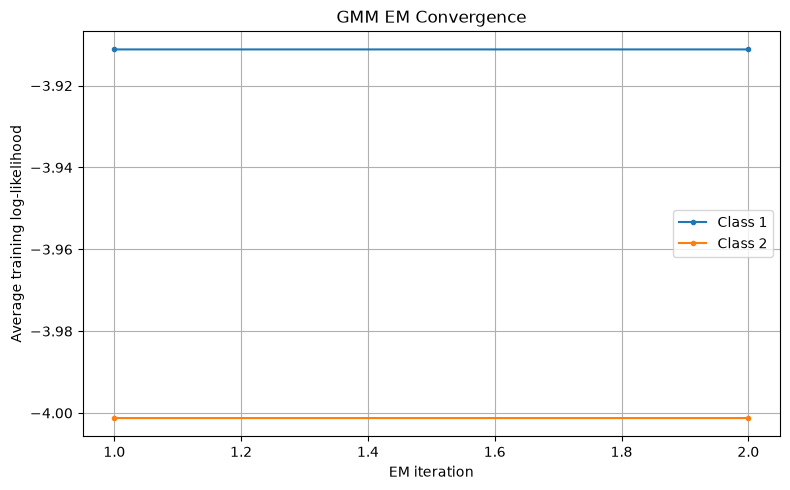

In [36]:
# --------------------------------------------------
# 12. Plot EM log-likelihood convergence
# --------------------------------------------------
plt.figure(figsize=(8, 5))

for class_index, model in enumerate(class_models):
    iterations = np.arange(1, len(model.log_likelihoods) + 1)
    plt.plot(iterations, model.log_likelihoods, marker="o",
             markersize=3, label=f"Class {class_index + 1}")

plt.xlabel("EM iteration")
plt.ylabel("Average training log-likelihood")
plt.title("GMM EM Convergence")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [37]:
# --------------------------------------------------
# 13. Classify synthetic test samples using log-likelihood
# --------------------------------------------------
X_test = np.vstack((X1_test, X2_test))
y_test = np.array([0] * len(X1_test) + [1] * len(X2_test))

# Equal class priors because both classes have the same training size.
class_scores = np.column_stack([
    model.score_samples(X_test) for model in class_models
])

y_pred = np.argmax(class_scores, axis=1)

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
accuracy = accuracy_score(y_test, y_pred)

print("Confusion matrix (rows = actual, columns = predicted):\\n", cm)
print(f"Accuracy: {accuracy * 100:.2f}%")
print("\\nClassification report:")
print(classification_report(
    y_test, y_pred,
    labels=[0, 1],
    target_names=["Class 1", "Class 2"],
    zero_division=0
))

Confusion matrix (rows = actual, columns = predicted):\n [[977  23]
 [ 34 966]]
Accuracy: 97.15%
\nClassification report:
              precision    recall  f1-score   support

     Class 1       0.97      0.98      0.97      1000
     Class 2       0.98      0.97      0.97      1000

    accuracy                           0.97      2000
   macro avg       0.97      0.97      0.97      2000
weighted avg       0.97      0.97      0.97      2000



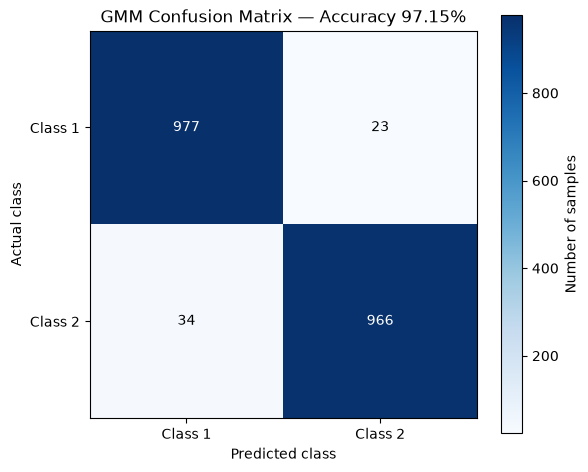

In [38]:
# --------------------------------------------------
# 14. Plot synthetic-data confusion matrix
# --------------------------------------------------
plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap="Blues")
plt.title(f"GMM Confusion Matrix — Accuracy {accuracy:.2%}")
plt.colorbar(label="Number of samples")
plt.xticks([0, 1], ["Class 1", "Class 2"])
plt.yticks([0, 1], ["Class 1", "Class 2"])
plt.xlabel("Predicted class")
plt.ylabel("Actual class")

threshold = cm.max() / 2
for i in range(2):
    for j in range(2):
        plt.text(j, i, str(cm[i, j]), ha="center", va="center",
                 color="white" if cm[i, j] > threshold else "black")

plt.tight_layout()
plt.show()

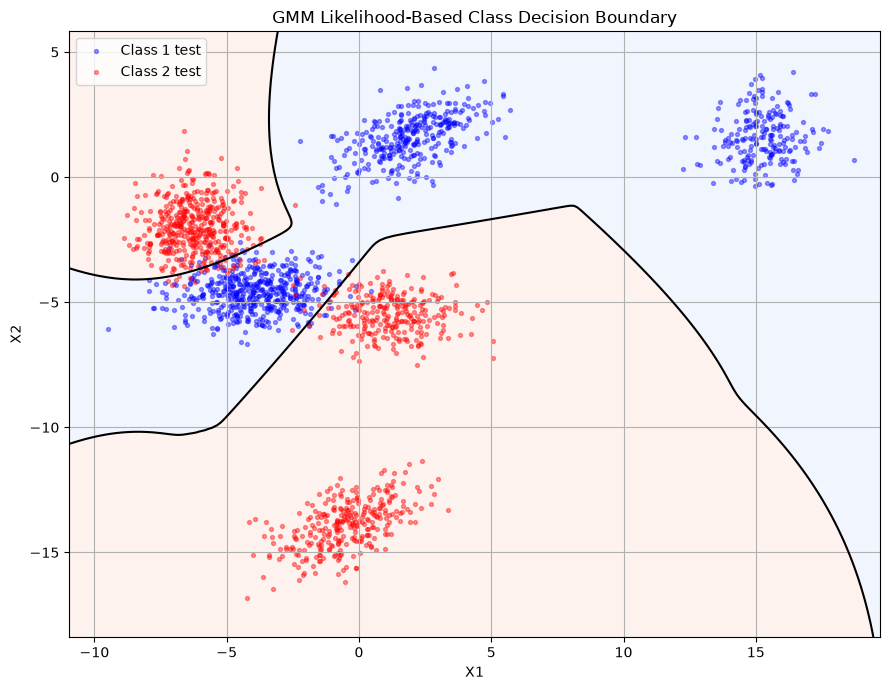

In [39]:
# --------------------------------------------------
# 15. Plot GMM decision boundary
# --------------------------------------------------
all_data = np.vstack((X1, X2))
x_min, x_max = all_data[:, 0].min() - 1, all_data[:, 0].max() + 1
y_min, y_max = all_data[:, 1].min() - 1, all_data[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 250),
    np.linspace(y_min, y_max, 250)
)
grid = np.column_stack((xx.ravel(), yy.ravel()))

grid_scores = np.column_stack([
    model.score_samples(grid) for model in class_models
])
grid_prediction = np.argmax(grid_scores, axis=1).reshape(xx.shape)
score_difference = (grid_scores[:, 0] - grid_scores[:, 1]).reshape(xx.shape)

plt.figure(figsize=(9, 7))
plt.contourf(xx, yy, grid_prediction, levels=[-0.5, 0.5, 1.5],
             alpha=0.12, cmap="coolwarm")
plt.contour(xx, yy, score_difference, levels=[0],
            colors="black", linewidths=1.5)
plt.scatter(X1_test[:, 0], X1_test[:, 1], s=8, alpha=0.4,
            color="blue", label="Class 1 test")
plt.scatter(X2_test[:, 0], X2_test[:, 1], s=8, alpha=0.4,
            color="red", label="Class 2 test")
plt.xlabel("X1")
plt.ylabel("X2")
plt.title("GMM Likelihood-Based Class Decision Boundary")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [40]:
# --------------------------------------------------
# 16. Load Development, Training and Testing Datasets
# --------------------------------------------------

import os
import numpy as np
from PIL import Image

# Actual assigned digits
assigned_digits = [0, 6, 9]

# Dataset paths
DEV_PATH = r"C:\Users\krith\OneDrive\Desktop\M.Tech\PR and ML\Team 4\dev"
TEST_PATH = r"C:\Users\krith\OneDrive\Desktop\M.Tech\PR and ML\Team 4\test"
TRAIN_PATH = r"C:\Users\krith\OneDrive\Desktop\M.Tech\PR and ML\Team 4\train"

def load_dataset(folder_path):

    images = []
    labels = []

    for digit in assigned_digits:

        digit_folder = os.path.join(folder_path, str(digit))

        if not os.path.isdir(digit_folder):
            raise FileNotFoundError(
                f"Missing folder: {digit_folder}"
            )

        image_files = sorted([
            f for f in os.listdir(digit_folder)
            if f.lower().endswith(
                (".png", ".jpg", ".jpeg", ".bmp")
            )
        ])

        if len(image_files) == 0:
            raise ValueError(
                f"No images found for digit {digit} "
                f"in {folder_path}"
            )

        for filename in image_files:

            image_path = os.path.join(
                digit_folder, filename
            )

            with Image.open(image_path) as image:
                image = image.convert("L")
                image = image.resize((28, 28))

                image_array = np.asarray(
                    image, dtype=np.float32
                ) / 255.0

            images.append(image_array)
            labels.append(digit)

    return np.array(images), np.array(labels)

# Load datasets
X_dev_images, y_dev = load_dataset(DEV_PATH)

X_train_images, y_train = load_dataset(TRAIN_PATH)

X_test_images, y_test_mnist = load_dataset(TEST_PATH)

print("Development:", X_dev_images.shape)
print("Training:", X_train_images.shape)
print("Testing:", X_test_images.shape)

Development: (3527, 28, 28)
Training: (14263, 28, 28)
Testing: (2947, 28, 28)


In [41]:
# --------------------------------------------------
# 17. Flatten MNIST Images
# --------------------------------------------------

# Convert 28 x 28 images into 784 features

X_train_pixels = X_train_images.reshape(
    len(X_train_images), 784
)

X_dev_pixels = X_dev_images.reshape(
    len(X_dev_images), 784
)

X_test_pixels = X_test_images.reshape(
    len(X_test_images), 784
)

print("Training data:", X_train_pixels.shape)
print("Development data:", X_dev_pixels.shape)
print("Testing data:", X_test_pixels.shape)

Training data: (14263, 784)
Development data: (3527, 784)
Testing data: (2947, 784)


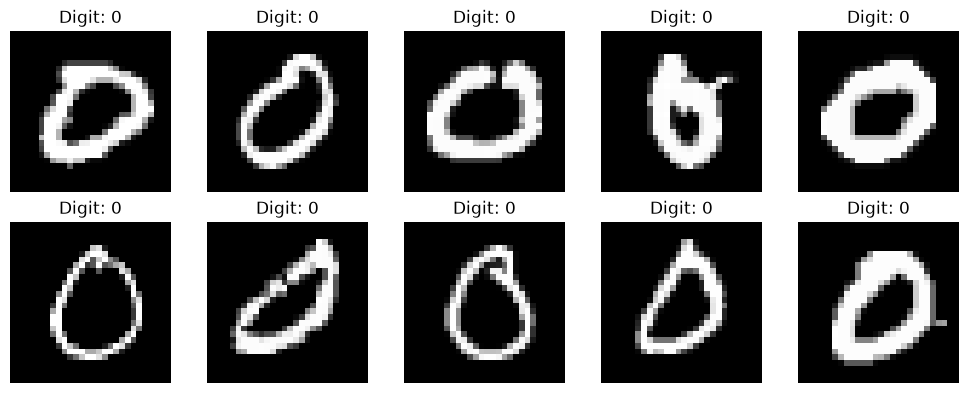

In [42]:
# --------------------------------------------------
# 17A. Display Sample MNIST Images
# --------------------------------------------------

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(X_train_images[i], cmap="gray")

    plt.title(f"Digit: {y_train[i]}")

    plt.axis("off")

plt.tight_layout()
plt.show()

In [43]:
# --------------------------------------------------
# 18. PCA Dimensionality Reduction
# --------------------------------------------------

from sklearn.decomposition import PCA

PCA_FEATURES = 40

pca = PCA(n_components=PCA_FEATURES, random_state=42)

X_train_pca = pca.fit_transform(X_train_pixels)

X_dev_pca = pca.transform(X_dev_pixels)

X_test_pca = pca.transform(X_test_pixels)

print("Original features:", X_train_pixels.shape[1])
print("Reduced features:", X_train_pca.shape[1])

print(
    "Variance retained:",
    round(100 * pca.explained_variance_ratio_.sum(), 2),
    "%"
)

Original features: 784
Reduced features: 40
Variance retained: 82.88 %


In [44]:
# --------------------------------------------------
# 19. Train GMMs for selected digits
# --------------------------------------------------
MAX_TRAIN_PER_DIGIT = 3000  # Set to None to use all training images
MNIST_COMPONENTS = 3

rng = np.random.default_rng(42)
mnist_models = {}

for digit in assigned_digits:
    digit_data = X_train_pca[y_train == digit]

    if MAX_TRAIN_PER_DIGIT is not None and len(digit_data) > MAX_TRAIN_PER_DIGIT:
        selected_indices = rng.choice(
            len(digit_data), size=MAX_TRAIN_PER_DIGIT, replace=False
        )
        digit_data = digit_data[selected_indices]

    model = GMM(
        K=MNIST_COMPONENTS,
        reg=1e-3,
        max_iter=100,
        tol=1e-4
    )
    model.fit(digit_data)
    mnist_models[digit] = model

    print(f"Digit {digit}: trained on {len(digit_data)} images")
    print("Learned mixture weights:", np.round(model.weights, 4))
    print("EM iterations:", len(model.log_likelihoods))

Digit 0: trained on 3000 images
Learned mixture weights: [0.393  0.2755 0.3314]
EM iterations: 14
Digit 6: trained on 3000 images
Learned mixture weights: [0.3236 0.3759 0.3004]
EM iterations: 53
Digit 9: trained on 3000 images
Learned mixture weights: [0.3716 0.2701 0.3583]
EM iterations: 65


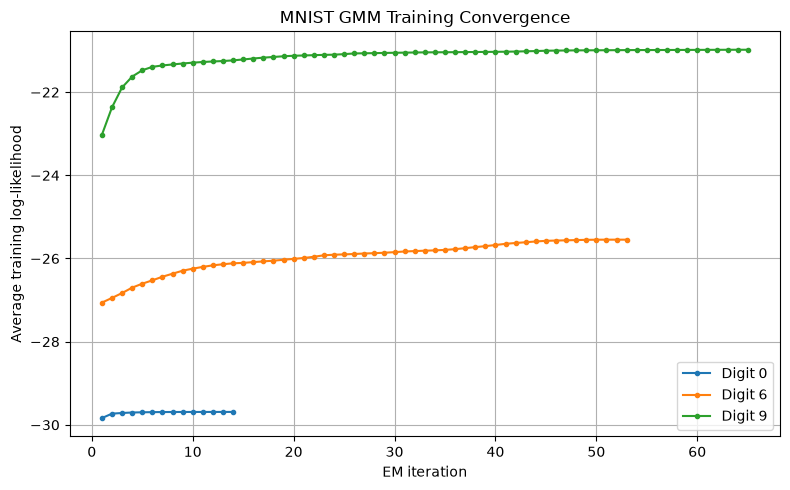

In [45]:
# --------------------------------------------------
# 20. Plot MNIST GMM log-likelihood convergence
# --------------------------------------------------
plt.figure(figsize=(8, 5))

for digit in assigned_digits:
    model = mnist_models[digit]
    iterations = np.arange(1, len(model.log_likelihoods) + 1)
    plt.plot(iterations, model.log_likelihoods,
             marker="o", markersize=3, label=f"Digit {digit}")

plt.xlabel("EM iteration")
plt.ylabel("Average training log-likelihood")
plt.title("MNIST GMM Training Convergence")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [46]:
# --------------------------------------------------
# 21. Classify MNIST test images
# --------------------------------------------------
mnist_scores = np.column_stack([
    mnist_models[digit].score_samples(X_test_pca)
    for digit in assigned_digits
])

predicted_indices = np.argmax(mnist_scores, axis=1)
y_pred_mnist = np.array(assigned_digits)[predicted_indices]

mnist_accuracy = accuracy_score(y_test_mnist, y_pred_mnist)
mnist_cm = confusion_matrix(
    y_test_mnist, y_pred_mnist, labels=assigned_digits
)

print(f"MNIST GMM test accuracy: {mnist_accuracy * 100:.2f}%")
print("\\nConfusion matrix (rows = actual, columns = predicted):\\n",
      mnist_cm)
print("\\nClassification report:")
print(classification_report(
    y_test_mnist,
    y_pred_mnist,
    labels=assigned_digits,
    target_names=[str(d) for d in assigned_digits],
    zero_division=0
))

MNIST GMM test accuracy: 99.49%
\nConfusion matrix (rows = actual, columns = predicted):\n [[ 978    0    2]
 [   7  946    5]
 [   1    0 1008]]
\nClassification report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       980
           6       1.00      0.99      0.99       958
           9       0.99      1.00      1.00      1009

    accuracy                           0.99      2947
   macro avg       0.99      0.99      0.99      2947
weighted avg       0.99      0.99      0.99      2947



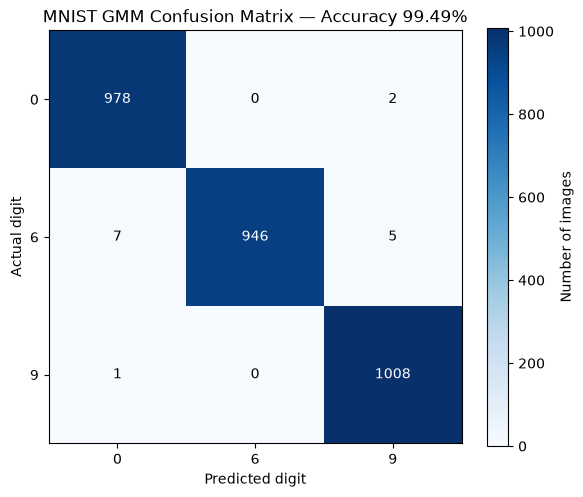

In [47]:
# --------------------------------------------------
# 22. Plot MNIST confusion matrix
# --------------------------------------------------
plt.figure(figsize=(6, 5))
plt.imshow(mnist_cm, cmap="Blues")
plt.title(f"MNIST GMM Confusion Matrix — Accuracy {mnist_accuracy:.2%}")
plt.colorbar(label="Number of images")
plt.xticks(range(len(assigned_digits)), assigned_digits)
plt.yticks(range(len(assigned_digits)), assigned_digits)
plt.xlabel("Predicted digit")
plt.ylabel("Actual digit")

threshold = mnist_cm.max() / 2
for i in range(len(assigned_digits)):
    for j in range(len(assigned_digits)):
        plt.text(
            j, i, str(mnist_cm[i, j]),
            ha="center", va="center",
            color="white" if mnist_cm[i, j] > threshold else "black"
        )

plt.tight_layout()
plt.show()

Number of misclassified images: 15


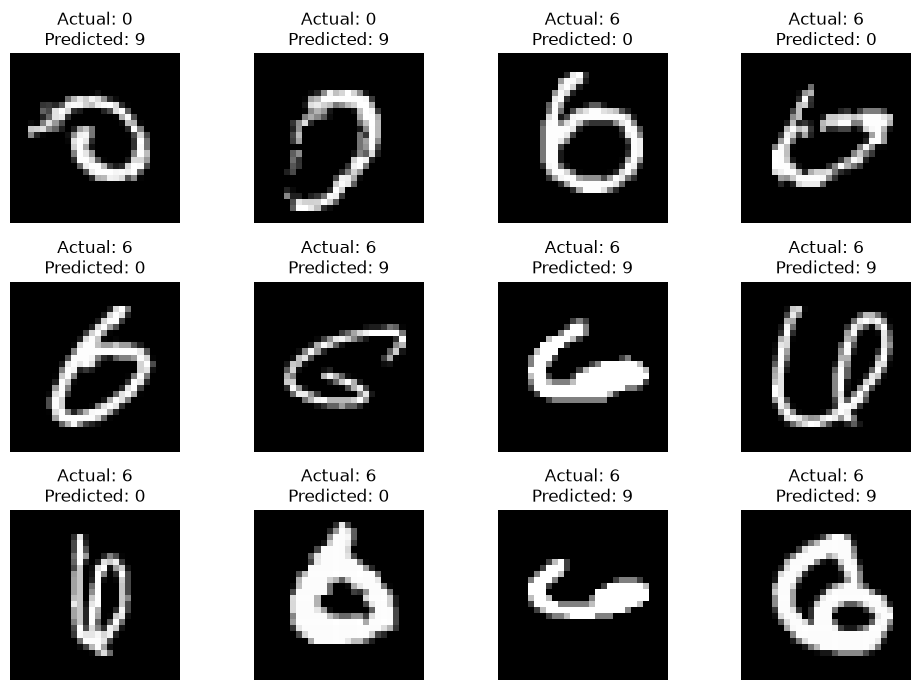

In [48]:
# --------------------------------------------------
# 23. Display misclassified MNIST images
# --------------------------------------------------
wrong_indices = np.where(y_test_mnist != y_pred_mnist)[0]
print("Number of misclassified images:", len(wrong_indices))

if len(wrong_indices) > 0:
    number_to_show = min(12, len(wrong_indices))
    plt.figure(figsize=(10, 7))

    for i, idx in enumerate(wrong_indices[:number_to_show]):
        plt.subplot(3, 4, i + 1)
        plt.imshow(X_test_images[idx], cmap="gray")
        plt.title(
            f"Actual: {y_test_mnist[idx]}\nPredicted: {y_pred_mnist[idx]}"
        )
        plt.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No misclassified images in this test set.")